# Exploratory data analysis: public procurement awards 2019-2022

**Data:** 3,557,158 EU contract award records (TED, 33 countries) and 142,870 World Bank contract-supplier rows, both 2019-2022, from the clean layer built by `python -m procurement.pipeline`.

**Key findings**

1. **The single-bid label is usable.** Of 2.88 million awarded contracts, 2.81 million (97.7%) have a valid number of offers. 32.3% received only one offer: a clear signal, without extreme class imbalance.
2. **Missing values are structural, not random.** 95% of raw rows without an offer count are lot rows with no award section or lots that were never awarded. Only 3,302 awarded rows simply omit it.
3. **Procedure type dominates.** Procedures without a call for competition are single-bid 86% of the time, by design. Competitive procedures alone: 30.6%. The prediction problem should focus on competitive procedures.
4. **Strong differences by country, sector, contract type and size:** from 60% (Slovenia) to 6% (Iceland); 52% for laboratory equipment vs 14% for construction work; 37.5% for supplies vs 13.5% for works; 38% for contracts under EUR 10k vs 14% above EUR 10M.
5. **9% of award values are implausibly low (< EUR 100)**, concentrated in Germany and the Netherlands and often linked to framework agreements. They are flagged, not deleted.
6. **Vendor-name standardisation cuts distinct names by about 36%**, e.g. 15+ spellings of Siemens Healthcare become one key.
7. **The sources connect through companies, not contracts:** hundreds of companies won both EU tenders and World Bank contracts. Correcting joint-venture repeats avoids USD 4.4 bn of double counting in World Bank totals.

All rates are descriptive associations. A high single-bid rate is a risk indicator worth investigating, not evidence of wrongdoing.

## 0. Setup

Run `python -m procurement.pipeline` first: it builds the database this notebook reads. The notebook only reads data (read-only connection). The SQL here is exploratory; the cleaning rules themselves live in `sql/clean/`.

In [1]:
# Make the project package importable whether the notebook runs from the
# project root (VS Code default) or from the notebooks/ folder.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from procurement import config

# Read-only connection: the notebook can never change the database.
connection = duckdb.connect(str(config.DATABASE_PATH), read_only=True)


def query(sql):
    """Run SQL against the project database and return a pandas DataFrame."""
    return connection.sql(sql).df()


# One chart style for the whole notebook: one bar colour, a grey reference
# line, light grid, no chart junk.
BAR_COLOUR = "#2a78d6"
REFERENCE_COLOUR = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.grid.axis": "x",
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#b5b4ad",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "font.size": 9,
})
pd.options.display.float_format = "{:,.2f}".format


def bar_chart(frame, label_column, value_column, title, xlabel,
              reference=None, reference_label=None, percent=False, height=None):
    """Horizontal bar chart, largest at the top, value printed at each bar end."""
    frame = frame.sort_values(value_column)
    height = height or max(2.2, 0.32 * len(frame) + 0.8)
    figure, axis = plt.subplots(figsize=(8, height))
    bars = axis.barh(frame[label_column].astype(str), frame[value_column], color=BAR_COLOUR, height=0.7)
    text_format = "{:.0%}" if percent else "{:,.0f}"
    for bar, value in zip(bars, frame[value_column]):
        axis.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + text_format.format(value),
                  va="center", fontsize=8, color="#0b0b0b")
    if reference is not None:
        axis.axvline(reference, color=REFERENCE_COLOUR, linestyle="--", linewidth=1)
        axis.text(reference, len(frame) - 0.3, f" {reference_label}", color=REFERENCE_COLOUR, fontsize=8, va="bottom")
    if percent:
        axis.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    axis.set_title(title, loc="left")
    axis.set_xlabel(xlabel)
    axis.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()


## 1. The data at a glance

The clean table `ted_awards` has **one row per contract award** (built by `sql/clean/clean_ted_awards.sql`).

In [3]:
overview = query("""
    SELECT
        notice_year,
        COUNT(*)                                          AS awards,
        COUNT(DISTINCT notice_id)                         AS notices,
        COUNT(DISTINCT buyer_country)                     AS countries,
        AVG(CASE WHEN award_status = 'awarded' THEN 1.0 ELSE 0.0 END) AS awarded_share
    FROM ted_awards
    GROUP BY notice_year
    ORDER BY notice_year
""")
overview

,notice_year,awards,notices,countries,awarded_share
0,2019,798690,264751,33,0.85
1,2020,864631,267587,33,0.80
2,2021,945685,285493,33,0.80
3,2022,948152,300612,33,0.79


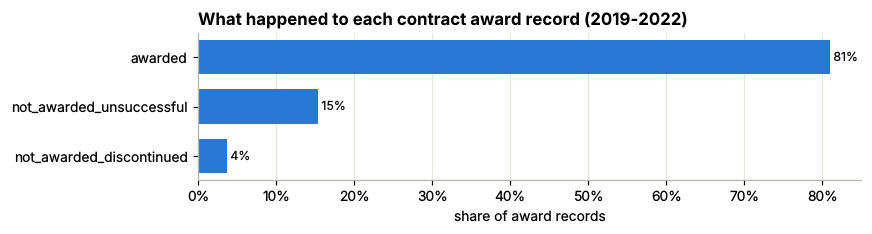

,award_status,awards,share
0,not_awarded_unsuccessful,547084,0.15
1,awarded,2879742,0.81
2,not_awarded_discontinued,130332,0.04


In [4]:
status = query("""
    SELECT award_status, COUNT(*) AS awards
    FROM ted_awards
    GROUP BY award_status
""")
status["share"] = status["awards"] / status["awards"].sum()
bar_chart(status, "award_status", "share", "What happened to each contract award record (2019-2022)",
          "share of award records", percent=True)
status

**Finding.** 3.56 million award records, about 0.8-0.95 million per year, across the same 33 countries every year. 81% were awarded; 15% were unsuccessful (no valid offers received) and 4% discontinued. The awarded share fell from 85% in 2019 to about 80% in 2020-2022. Unsuccessful procedures are a finding in their own right: some tenders attract no acceptable offer at all.

## 2. Why is the number of offers missing for a third of the raw rows?

Before using `number_offers` as the ML target, every missing value is traced to a reason.

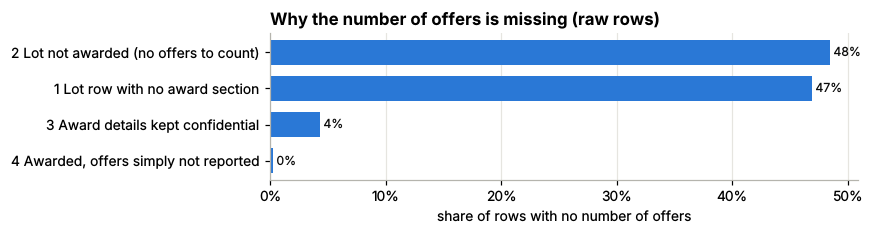

,reason,raw_rows,share_of_missing
0,1 Lot row with no award section,667385,0.47
1,2 Lot not awarded (no offers to count),689219,0.48
2,3 Award details kept confidential,61655,0.04
3,"4 Awarded, offers simply not reported",3302,0.00


In [5]:
# Start from the RAW data (4.3M rows) and explain every missing number of offers.
missing_offers = query("""
    SELECT
        CASE
            WHEN id_award IS NULL THEN '1 Lot row with no award section'
            WHEN info_on_non_award IS NOT NULL THEN '2 Lot not awarded (no offers to count)'
            WHEN info_unpublished = 'Y' THEN '3 Award details kept confidential'
            ELSE '4 Awarded, offers simply not reported'
        END AS reason,
        COUNT(*) AS raw_rows
    FROM raw_ted_awards
    WHERE number_offers IS NULL OR TRIM(number_offers) = ''
    GROUP BY reason
    ORDER BY reason
""")
missing_offers["share_of_missing"] = missing_offers["raw_rows"] / missing_offers["raw_rows"].sum()
bar_chart(missing_offers, "reason", "share_of_missing", "Why the number of offers is missing (raw rows)",
          "share of rows with no number of offers", percent=True)
missing_offers

**Finding.** All 1,421,561 raw rows without an offer count are explained:
- **47%** are lot rows with no award section (the CSV format lists lots and awards on separate rows; see the TED codebook, section 3.7).
- **48%** are lots that were never awarded, so there were no offers to count.
- **4%** are awards whose details the buyer marked as confidential (utilities forms).
- **0.2% (3,302 rows)** are awarded contracts that simply do not report it.

**Implication:** the target is missing for structural reasons, not at random among awarded contracts. After cleaning, 97.7% of awarded contracts have a usable label, so dropping the rest does not bias the sample in a hidden way.

## 3. How many offers do contracts receive?

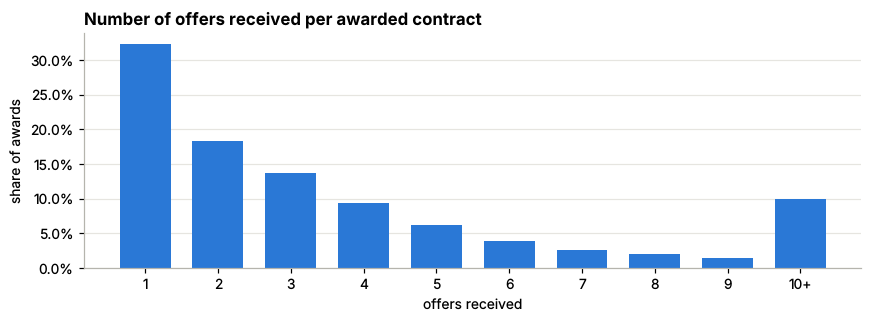

,offers,awards,share
2,1,909084,0.32
0,2,516593,0.18
7,3,385871,0.14
8,4,264897,0.09
3,5,174400,0.06
4,6,110821,0.04
5,7,75040,0.03
1,8,55887,0.02
6,9,41128,0.01
9,10+,280597,0.10


In [6]:
offers = query("""
    SELECT
        CASE WHEN number_offers >= 10 THEN '10+' ELSE CAST(number_offers AS VARCHAR) END AS offers,
        COUNT(*) AS awards
    FROM ted_awards
    WHERE award_status = 'awarded' AND number_offers IS NOT NULL
    GROUP BY 1
""")
offers["sort_key"] = offers["offers"].str.replace("+", "", regex=False).astype(int)
offers = offers.sort_values("sort_key")
offers["share"] = offers["awards"] / offers["awards"].sum()

figure, axis = plt.subplots(figsize=(8, 3))
axis.bar(offers["offers"], offers["share"], color=BAR_COLOUR, width=0.7)
axis.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axis.grid(axis="x", visible=False)
axis.grid(axis="y", visible=True)
axis.set_title("Number of offers received per awarded contract", loc="left")
axis.set_xlabel("offers received")
axis.set_ylabel("share of awards")
plt.tight_layout()
plt.show()
offers[["offers", "awards", "share"]]

In [7]:
label_summary = query("""
    SELECT
        COUNT(*) FILTER (WHERE is_single_bid IS NOT NULL) AS labelled_awards,
        COUNT(*) FILTER (WHERE is_single_bid = 1)         AS single_bid_awards,
        AVG(is_single_bid)                                AS single_bid_rate
    FROM ted_awards
""")
OVERALL_RATE = label_summary["single_bid_rate"].iloc[0]
label_summary

,labelled_awards,single_bid_awards,single_bid_rate
0,2814318,909084,0.32


**Finding.** 32.3% of labelled awards received exactly one offer, 18% two, 14% three, and 10% ten or more. For the classifier this is a 1 : 2 class ratio: imbalanced enough to report precision and recall rather than accuracy, but not so extreme that special resampling is required.

## 4. Where is single bidding most common?

Single-bid rate = share of labelled awards that received exactly one offer. Groups with too few awards are hidden, because their rates are unstable. These are associations, not causes.

In [8]:
def single_bid_rate_by(column, minimum_awards=1000, where="TRUE"):
    """Single-bid rate per value of `column`, for groups with enough labelled awards."""
    return query(f"""
        SELECT
            {column} AS grp,
            COUNT(*)            AS labelled_awards,
            AVG(is_single_bid)  AS single_bid_rate
        FROM ted_awards
        WHERE is_single_bid IS NOT NULL AND {column} IS NOT NULL AND {where}
        GROUP BY {column}
        HAVING COUNT(*) >= {minimum_awards}
        ORDER BY single_bid_rate DESC
    """)

### 4.1 By country

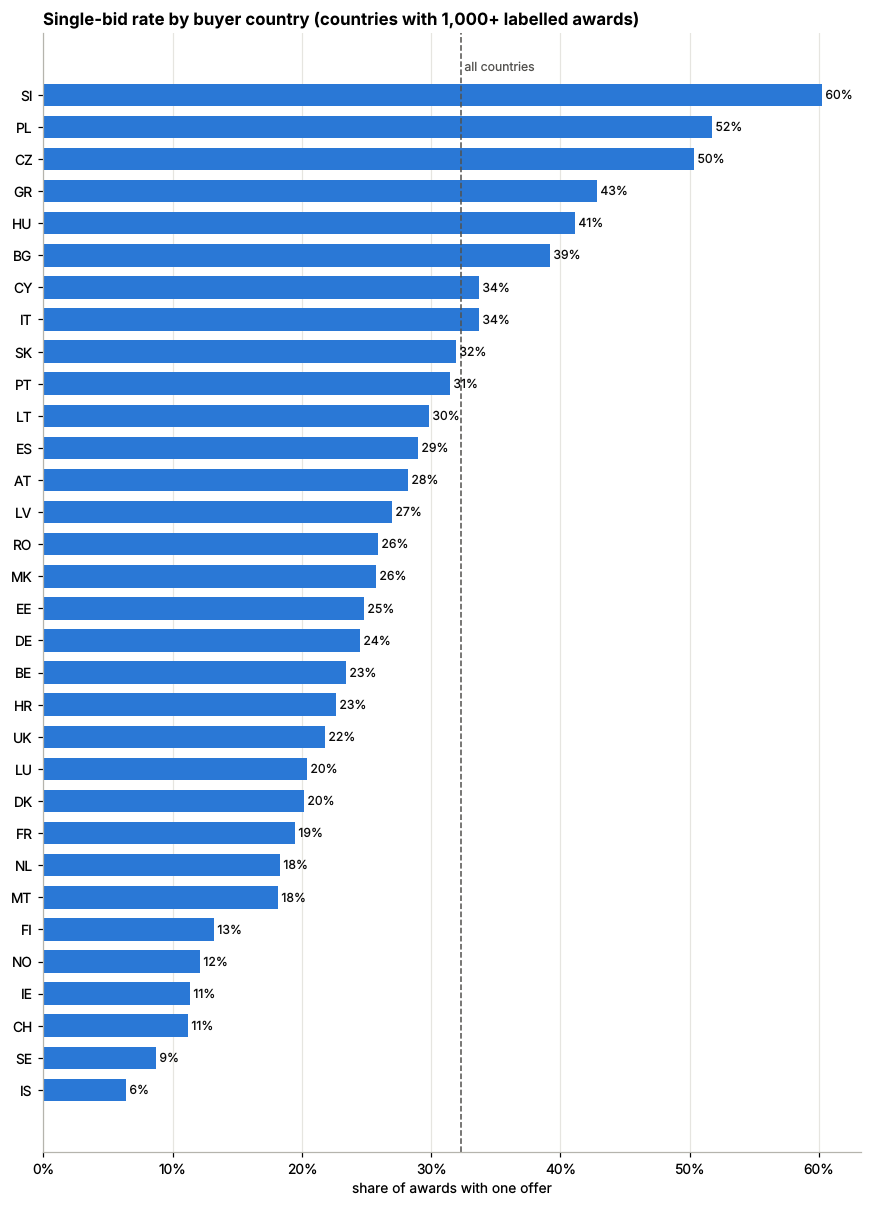

,grp,labelled_awards,single_bid_rate
0,SI,125480,0.60
1,PL,524221,0.52
2,CZ,115167,0.50
3,GR,33415,0.43
4,HU,40854,0.41
5,BG,65596,0.39
6,CY,2874,0.34
7,IT,100728,0.34
8,SK,15216,0.32
9,PT,26009,0.31


In [9]:
by_country = single_bid_rate_by("buyer_country")
bar_chart(by_country, "grp", "single_bid_rate", "Single-bid rate by buyer country (countries with 1,000+ labelled awards)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="all countries", percent=True)
by_country

**Finding.** Single-bid rates differ by a factor of ten between countries: Slovenia 60%, Poland 52%, Czechia 50%, against 9% for Sweden and 6% for Iceland. France, the second-largest publisher, is at 19%.

**Caution.** Countries differ in what they buy, how they split tenders into lots and which contracts they publish on TED, so this is not a ranking of integrity. Country will be a strong model feature; the reasons behind the differences need the sector and procedure views below.

### 4.2 By procedure type

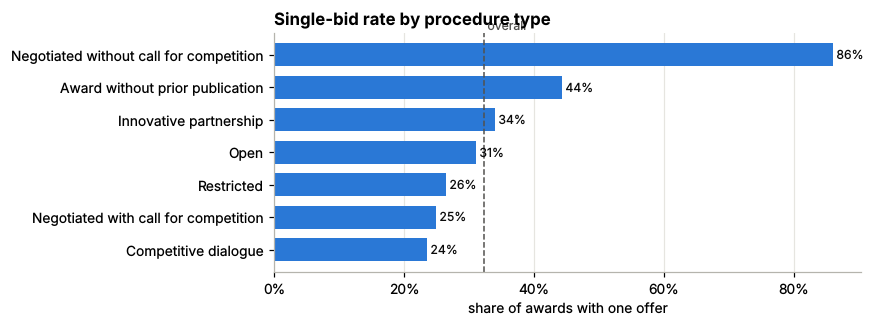

,grp,labelled_awards,single_bid_rate
0,Negotiated without call for competition,79276,0.86
1,Award without prior publication,36117,0.44
2,Innovative partnership,1239,0.34
3,Open,2469524,0.31
4,Restricted,111740,0.26
5,Negotiated with call for competition,106353,0.25
6,Competitive dialogue,3019,0.24


In [10]:
by_procedure = single_bid_rate_by("procedure_type")
bar_chart(by_procedure, "grp", "single_bid_rate", "Single-bid rate by procedure type",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
by_procedure

**Finding.** Negotiated procedures **without** a call for competition are single-bid 86% of the time, and awards without prior publication 44%. These procedures do not invite open competition, so one offer is expected by design. Competitive procedures (open, restricted, negotiated with a call, competitive dialogue, innovative partnership) are single-bid 30.6% of the time; open procedures 31%.

**Implication for Phase 5:** the useful question is *"will this competitive tender attract only one bidder?"* The model should train on competitive procedures; non-competitive ones would only teach it something already known from the procedure type.

### 4.3 By contract features

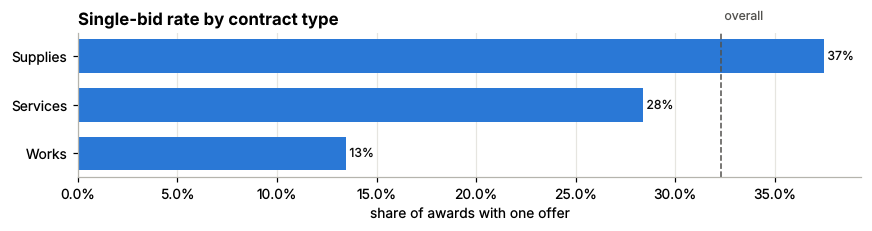

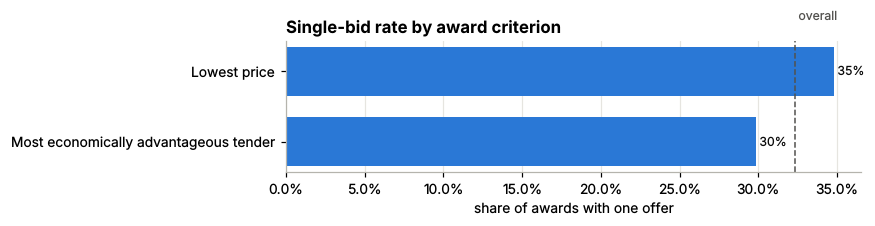

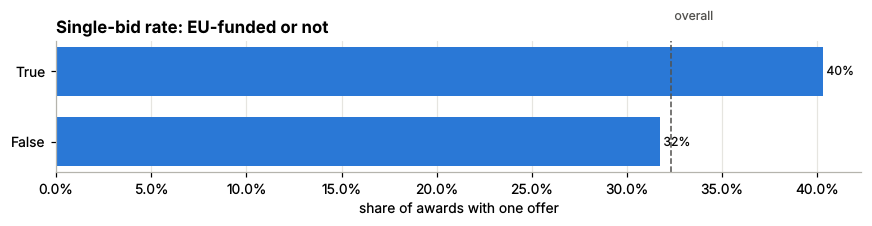

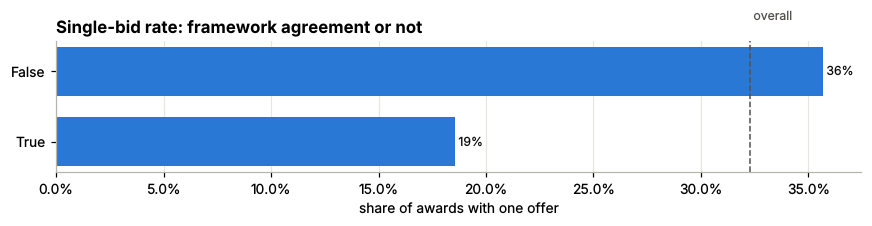

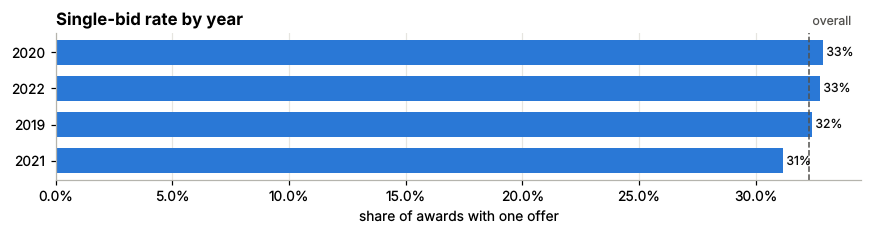

In [11]:
for column, title in [
    ("contract_type", "Single-bid rate by contract type"),
    ("award_criterion", "Single-bid rate by award criterion"),
    ("is_eu_funded", "Single-bid rate: EU-funded or not"),
    ("is_framework_agreement", "Single-bid rate: framework agreement or not"),
    ("notice_year", "Single-bid rate by year"),
]:
    table = single_bid_rate_by(column)
    bar_chart(table, "grp", "single_bid_rate", title, "share of awards with one offer",
              reference=OVERALL_RATE, reference_label="overall", percent=True)

**Findings.**
- **Contract type:** supplies 37.5%, services 28.4%, works 13.5%.
- **Award criterion:** lowest price 34.8% vs best value (MEAT) 29.9%.
- **EU funding:** EU-funded contracts 40.3% vs 31.7% for others.
- **Framework agreements:** 18.5% vs 35.7% for single contracts.
- **Year:** stable between 31% and 33%, so no strong time trend in this period.

These are associations: EU-funded contracts, for example, are concentrated in certain countries and sectors, which may explain part of their higher rate.

### 4.4 By sector

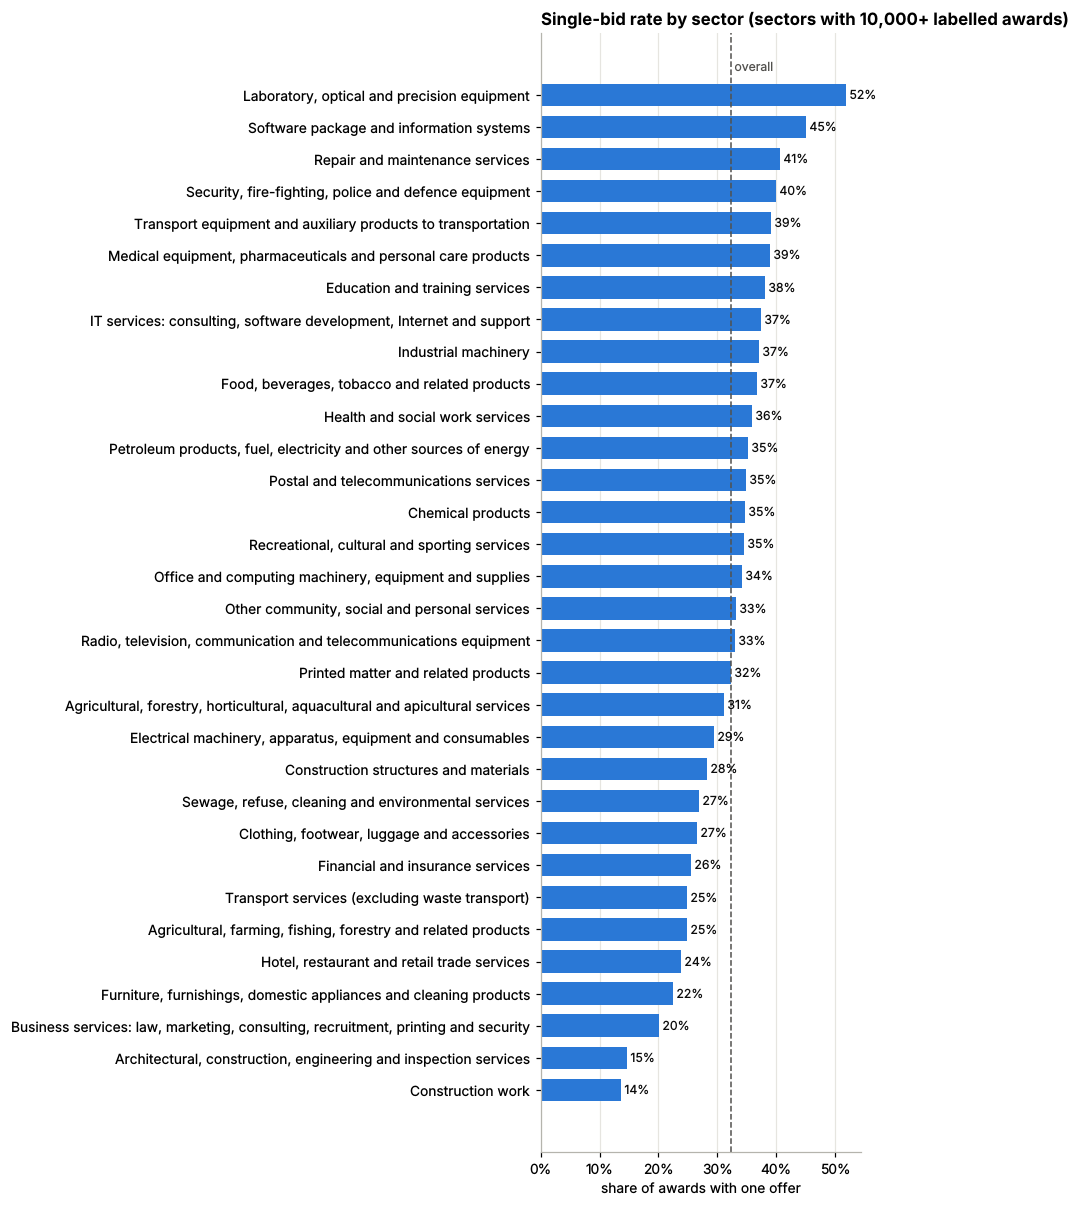

,grp,labelled_awards,single_bid_rate
0,"Laboratory, optical and precision equipment",43112,0.52
1,Software package and information systems,24417,0.45
2,Repair and maintenance services,101804,0.41
3,"Security, fire-fighting, police and defence eq...",18768,0.40
4,Transport equipment and auxiliary products to ...,83710,0.39
5,"Medical equipment, pharmaceuticals and persona...",908396,0.39
6,Education and training services,54724,0.38
7,"IT services: consulting, software development,...",60884,0.37
8,Industrial machinery,20460,0.37
9,"Food, beverages, tobacco and related products",163710,0.37


In [12]:
by_sector = single_bid_rate_by("cpv_division_name", minimum_awards=10000)
bar_chart(by_sector, "grp", "single_bid_rate", "Single-bid rate by sector (sectors with 10,000+ labelled awards)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
by_sector

**Finding.** Specialised supplies have the highest rates: laboratory and precision equipment 52%, software packages 45%, repair and maintenance 41%. Construction work (14%) and architecture and engineering services (15%) are the lowest. Medical equipment and pharmaceuticals, by far the largest sector (908,396 labelled awards, a third of the total), is at 39%. Sector (CPV division) will be an important feature.

### 4.5 By contract value

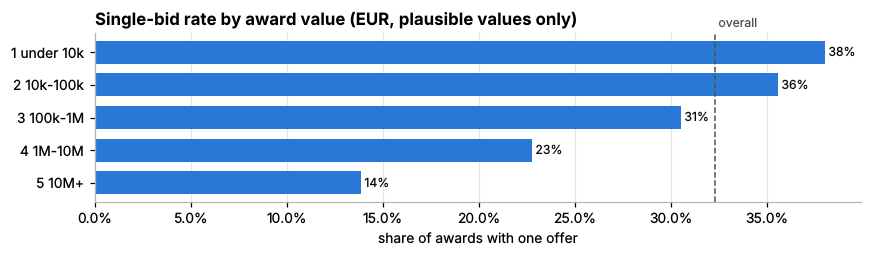

,value_band,labelled_awards,single_bid_rate
0,1 under 10k,755144,0.38
1,2 10k-100k,720845,0.36
2,3 100k-1M,753985,0.31
3,4 1M-10M,248033,0.23
4,5 10M+,59894,0.14


In [13]:
by_value = query("""
    SELECT
        CASE
            WHEN award_value_eur < 10000      THEN '1 under 10k'
            WHEN award_value_eur < 100000     THEN '2 10k-100k'
            WHEN award_value_eur < 1000000    THEN '3 100k-1M'
            WHEN award_value_eur < 10000000   THEN '4 1M-10M'
            ELSE                                   '5 10M+'
        END AS value_band,
        COUNT(*)           AS labelled_awards,
        AVG(is_single_bid) AS single_bid_rate
    FROM ted_awards
    WHERE is_single_bid IS NOT NULL AND award_value_quality = 'plausible'
    GROUP BY value_band
    ORDER BY value_band
""")
bar_chart(by_value, "value_band", "single_bid_rate", "Single-bid rate by award value (EUR, plausible values only)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
by_value

**Finding.** Smaller contracts are more often single-bid: 38% under EUR 10k, falling steadily to 14% above EUR 10M. Larger contracts appear to attract more competition.

**Caution for the model:** the *final award value* is only known after the tender. To predict before publication, Phase 5 must use the *estimated* value or other information available at publication time. Using the award value would leak information from the future.

## 5. Contract values: what is plausible?

In [14]:
value_quality = query("""
    SELECT award_value_quality, COUNT(*) AS awards
    FROM ted_awards
    WHERE award_status = 'awarded'
    GROUP BY 1
""")
value_quality["share"] = value_quality["awards"] / value_quality["awards"].sum()
value_quality.sort_values("awards", ascending=False)

,award_value_quality,awards,share
0,plausible,2550975,0.89
3,too_low,260223,0.09
2,missing,67014,0.02
1,too_high,1530,0.00


In [15]:
# Where do the implausibly low values (< 100 EUR) come from?
too_low = query("""
    SELECT
        buyer_country,
        COUNT(*) FILTER (WHERE award_value_quality = 'too_low') AS too_low_awards,
        AVG(CASE WHEN award_value_quality = 'too_low' THEN 1.0 ELSE 0.0 END) AS too_low_share,
        AVG(CASE WHEN award_value_quality = 'too_low' AND is_framework_agreement THEN 1.0
                 WHEN award_value_quality = 'too_low' THEN 0.0 END) AS framework_share_of_too_low
    FROM ted_awards
    WHERE award_status = 'awarded'
    GROUP BY buyer_country
    ORDER BY too_low_awards DESC
    LIMIT 8
""")
too_low

,buyer_country,too_low_awards,too_low_share,framework_share_of_too_low
0,DE,120075,0.39,0.38
1,RO,29527,0.08,0.00
2,NL,17384,0.44,0.37
3,PL,16150,0.03,0.01
4,FR,15207,0.04,0.76
5,UK,13532,0.15,0.32
6,ES,10410,0.06,0.18
7,SE,7520,0.10,0.25


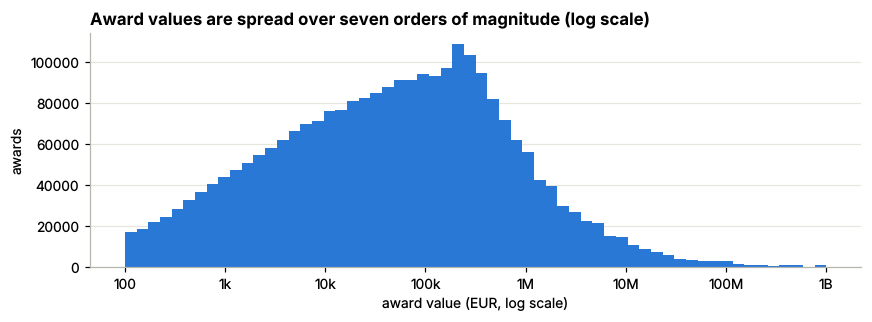

,p25,median,p75,mean
0,"6,388.91","54,360.00","316,197.01","2,175,036.04"


In [16]:
values = query("""
    SELECT LOG10(award_value_eur) AS log_value
    FROM ted_awards
    WHERE award_status = 'awarded' AND award_value_quality = 'plausible'
""")
figure, axis = plt.subplots(figsize=(8, 3))
axis.hist(values["log_value"], bins=60, color=BAR_COLOUR)
axis.set_xticks(range(2, 10))
axis.set_xticklabels(["100", "1k", "10k", "100k", "1M", "10M", "100M", "1B"])
axis.grid(axis="x", visible=False)
axis.grid(axis="y", visible=True)
axis.set_title("Award values are spread over seven orders of magnitude (log scale)", loc="left")
axis.set_xlabel("award value (EUR, log scale)")
axis.set_ylabel("awards")
plt.tight_layout()
plt.show()
query("""
    SELECT
        QUANTILE_CONT(award_value_eur, 0.25) AS p25,
        MEDIAN(award_value_eur)              AS median,
        QUANTILE_CONT(award_value_eur, 0.75) AS p75,
        AVG(award_value_eur)                 AS mean
    FROM ted_awards
    WHERE award_status = 'awarded' AND award_value_quality = 'plausible'
""")

**Findings.**
- 89% of awarded contracts have a plausible value, 9% are below EUR 100 (`too_low`), 2% are missing and 0.05% are EUR 1 billion or more (`too_high`).
- Implausibly low values are concentrated: 120,075 in Germany (39% of German awards) and 44% of Dutch awards. In France, 76% of them are framework agreements, where the value is often a symbolic or unit price. They are **flagged, not deleted**, so analyses can exclude them explicitly.
- Plausible values are extremely skewed: median EUR 54,360, mean EUR 2.2 million, so analyses use medians and log scales rather than means.

## 6. Vendor names: how messy, and how much does standardisation help?

In [17]:
# How standardisation groups different spellings of the same company.
query("""
    SELECT winner_name_std, winner_name, COUNT(*) AS awards
    FROM ted_awards
    WHERE winner_name_std LIKE 'siemens healthcare%'
    GROUP BY ALL
    ORDER BY winner_name_std, awards DESC
    LIMIT 15
""")

,winner_name_std,winner_name,awards
0,siemens healthcare,Siemens Healthcare Sp. z o.o.,494
1,siemens healthcare,Siemens Healthcare GmbH,422
2,siemens healthcare,SIEMENS HEALTHCARE SRL,284
3,siemens healthcare,"Siemens Healthcare, s.r.o.",234
4,siemens healthcare,"SIEMENS HEALTHCARE, S.L.U.",118
5,siemens healthcare,"Siemens Healthcare, S. L. U.",105
6,siemens healthcare,Siemens Healthcare S.R.L.,97
7,siemens healthcare,Siemens Healthcare AB,75
8,siemens healthcare,Siemens Healthcare Sp. z o. o.,70
9,siemens healthcare,Siemens Healthcare Oy,66


In [18]:
query("""
    SELECT
        COUNT(DISTINCT winner_name)     AS distinct_raw_names,
        COUNT(DISTINCT winner_name_std) AS distinct_standardised_names,
        1 - COUNT(DISTINCT winner_name_std) / COUNT(DISTINCT winner_name) AS reduction
    FROM ted_awards
    WHERE award_status = 'awarded'
""")

,distinct_raw_names,distinct_standardised_names,reduction
0,720095,462893,0.36


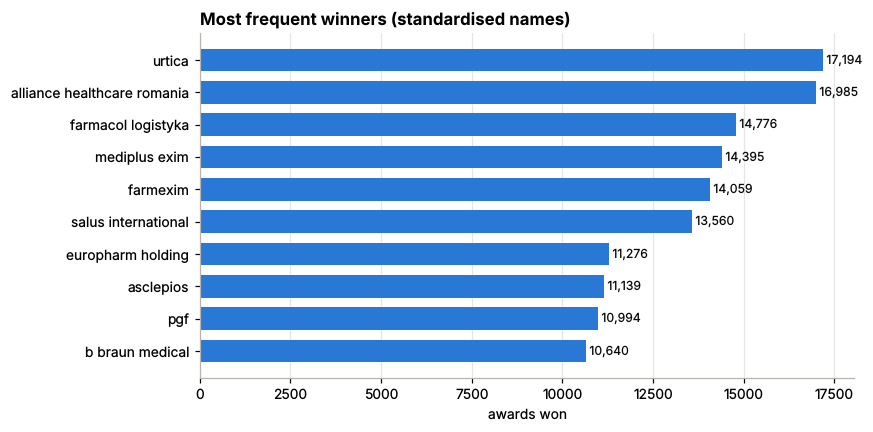

,winner_name_std,awards,buyer_countries
0,urtica,17194,1
1,alliance healthcare romania,16985,1
2,farmacol logistyka,14776,1
3,mediplus exim,14395,1
4,farmexim,14059,1
5,salus international,13560,1
6,europharm holding,11276,1
7,asclepios,11139,1
8,pgf,10994,1
9,b braun medical,10640,17


In [19]:
top_vendors = query("""
    SELECT winner_name_std, COUNT(*) AS awards, COUNT(DISTINCT buyer_country) AS buyer_countries
    FROM ted_awards
    WHERE award_status = 'awarded' AND winner_name_std IS NOT NULL
    GROUP BY 1
    ORDER BY awards DESC
    LIMIT 10
""")
bar_chart(top_vendors, "winner_name_std", "awards", "Most frequent winners (standardised names)", "awards won")
top_vendors

**Findings.**
- One company group appears under many spellings: Siemens Healthcare has 15+ variants across legal forms and countries, all mapped to `siemens healthcare`.
- Standardisation reduces distinct winner names by about 36%.
- The most frequent winners by **number of awards** are pharmaceutical and medical distributors in Romania and Poland. Medical tenders are split into very many small lots, so award counts are not the same as money won. Phase 3 measures concentration by value as well as count.

**Limitations (deliberate):** different subsidiaries (`siemens healthcare` vs `siemens`), translated names and spelling mistakes are not merged. Aggressive fuzzy matching could merge unrelated companies; this rule is transparent and conservative.

## 7. World Bank contracts

In [20]:
wb_overview = query("""
    SELECT
        signing_year,
        COUNT(DISTINCT contract_id)       AS contracts,
        SUM(amount_usd_for_totals) / 1e9  AS total_usd_bn,
        COUNT(DISTINCT borrower_country)  AS borrower_countries
    FROM world_bank_awards
    GROUP BY signing_year
    ORDER BY signing_year
""")
wb_overview

,signing_year,contracts,total_usd_bn,borrower_countries
0,2019,15474,6.64,137
1,2020,40504,16.01,143
2,2021,40121,19.44,149
3,2022,40485,15.32,146


In [21]:
query("""
    SELECT
        SUM(amount_usd) / 1e9            AS naive_total_usd_bn,
        SUM(amount_usd_for_totals) / 1e9 AS corrected_total_usd_bn,
        (SUM(amount_usd) - SUM(amount_usd_for_totals)) / 1e9 AS double_counted_usd_bn
    FROM world_bank_awards
""")

,naive_total_usd_bn,corrected_total_usd_bn,double_counted_usd_bn
0,61.83,57.41,4.42


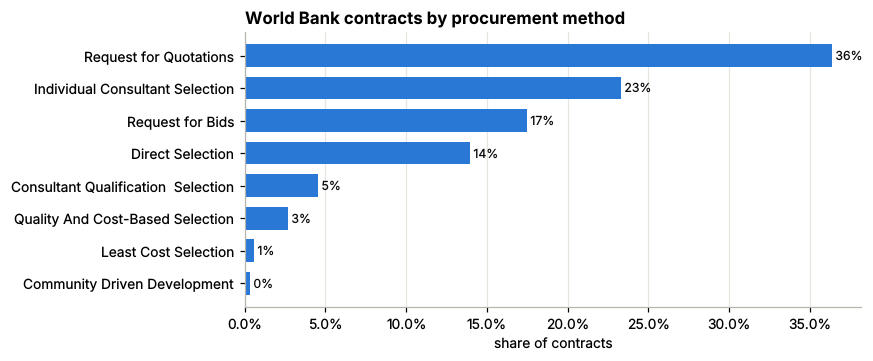

,procurement_method,contracts,share
0,Request for Quotations,49678,0.36
1,Individual Consultant Selection,31822,0.23
2,Request for Bids,23886,0.17
3,Direct Selection,19020,0.14
4,Consultant Qualification Selection,6204,0.05
5,Quality And Cost-Based Selection,3649,0.03
6,Least Cost Selection,776,0.01
7,Community Driven Development,484,0.00


In [22]:
wb_methods = query("""
    SELECT procurement_method, COUNT(DISTINCT contract_id) AS contracts
    FROM world_bank_awards
    GROUP BY 1
    ORDER BY contracts DESC
    LIMIT 8
""")
wb_methods["share"] = wb_methods["contracts"] / query(
    "SELECT COUNT(DISTINCT contract_id) AS n FROM world_bank_awards")["n"].iloc[0]
bar_chart(wb_methods, "procurement_method", "share", "World Bank contracts by procurement method",
          "share of contracts", percent=True)
wb_methods

**Findings.**
- 136,584 World Bank-financed contracts worth USD 57.4 billion, in 137-149 borrower countries per year. 2019 is partial because the source starts at fiscal year 2020 (July 2019).
- Summing amounts naively gives USD 61.8 billion: joint-venture contracts repeat the full amount for each partner, so USD 4.4 billion (7.7%) would be double counted. `amount_usd_for_totals` corrects this.
- Requests for quotations (36%) and individual consultant selection (23%) are the most common methods; direct selection, a non-competitive method, accounts for 14% of contracts.
- The World Bank data has no number of offers, so it adds global coverage and vendor information, not single-bid labels.

## 8. Linking the two sources

The sources describe different markets (EU public buyers vs. World Bank-financed projects), so there is no shared contract ID. The link is the **company**: the same standardised name from the same country.

In [23]:
# Companies that appear in BOTH sources: same standardised name AND same country.
both_sources = query("""
    WITH eu_winners AS (
        SELECT winner_name_std AS name_std, winner_country AS country, COUNT(*) AS eu_awards
        FROM ted_awards
        WHERE award_status = 'awarded' AND winner_name_std IS NOT NULL
        GROUP BY 1, 2
    ),
    world_bank_suppliers AS (
        SELECT supplier_name_std AS name_std, supplier_country_code AS country,
               COUNT(DISTINCT contract_id) AS world_bank_contracts
        FROM world_bank_awards
        WHERE supplier_name_std IS NOT NULL
        GROUP BY 1, 2
    )
    SELECT name_std, country, eu_awards, world_bank_contracts
    FROM eu_winners
    INNER JOIN world_bank_suppliers USING (name_std, country)
    ORDER BY world_bank_contracts DESC
""")
print(f"{len(both_sources):,} companies won EU tenders and World Bank contracts (2019-2022)")
both_sources.head(10)

678 companies won EU tenders and World Bank contracts (2019-2022)


,name_std,country,eu_awards,world_bank_contracts
0,sinohydro,CN,3,42
1,sofreco,FR,3,32
2,artelia,FR,447,20
3,eptisa servicios de ingenieria,ES,26,17
4,china meheco,CN,7,13
5,deloitte touche tohmatsu india,IN,1,12
6,ge medical systems,FR,119,12
7,sd biosensor,KR,3,10
8,coba consultores de engenharia e ambiente,PT,18,10
9,eta2u,RO,170,10


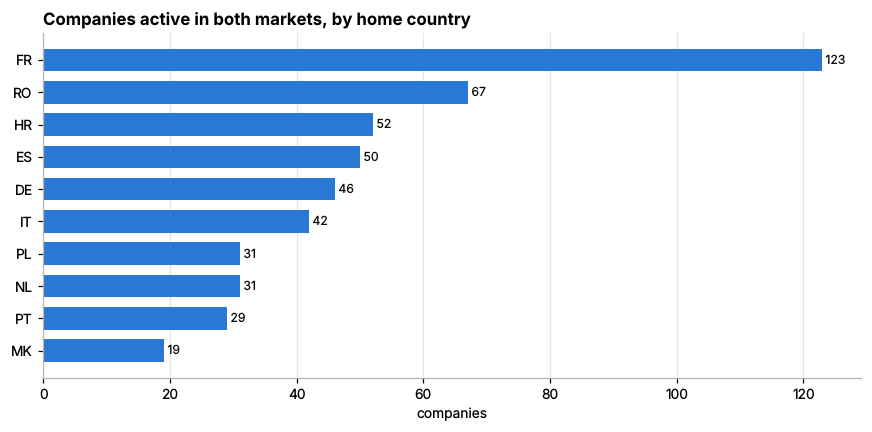

In [24]:
link_countries = both_sources.groupby("country").size().reset_index(name="companies")
link_countries = link_countries.sort_values("companies", ascending=False).head(10)
bar_chart(link_countries, "country", "companies", "Companies active in both markets, by home country", "companies")

**Finding.** Matching on standardised name **and** country finds 678 companies that won both EU tenders and World Bank contracts, mainly engineering consultancies and equipment suppliers (for example Artelia, France: 447 EU awards and 20 World Bank contracts). The two sources are therefore connected through **companies**, not contracts.

**How the join works:** an inner join of EU winners and World Bank suppliers on `(name_std, country)`. Requiring the same country avoids merging unrelated companies with similar names. Exact matching gives a conservative lower bound; fuzzy matching could find more pairs later.

## 9. Conclusions and decisions for the next phases

| Finding | Decision |
|---|---|
| 97.7% of awarded contracts have a valid offer count | Use `is_single_bid` as the ML target; train only on awarded, labelled contracts |
| Non-competitive procedures are single-bid by design (86%) | Phase 5 trains on competitive procedures only |
| Final award value is known only after the tender | Do not use it as a model feature (leakage); use information available at publication |
| Country, sector, contract type, criterion, EU funding, framework and size all matter | Candidate features for Phase 5 |
| 9% implausibly low values, very skewed values | Use `award_value_quality = 'plausible'`, medians and log scales for value analysis |
| Award counts are not money | Phase 3 measures vendor concentration by value and by count |
| Sources connect through companies | Phase 3 builds a vendor dimension using `(name_std, country)` |

In [25]:
connection.close()